# Tutorial 2 · The IBM 5-qubit "bowtie", rebuilt in the Quantcore PDK

**What it is.** IBM's first cloud processor (ibmqx2 *Yorktown* / ibmqx4 *Tenerife*, 2016–2021): five fixed-frequency
transmons and two bus resonators. Each bus couples three qubits — Q0, Q1, Q2 on one, Q2, Q3, Q4 on the other — so
the coupling graph is two triangles sharing Q2: the *bowtie*. Each qubit has its own readout resonator and line;
two-qubit gates are cross-resonance gates on the bus-mediated exchange J.

**Source and licence.** No layout of the chip is public. IBM's published device data set the topology and the
targets: the ibmqx2 Hamiltonian and properties (Qiskit `FakeYorktown`, 2021-03-15, `qiskit-ibm-runtime`,
Apache-2.0) and the ibmqx4 bus frequencies (arXiv:1805.10478). The layout is ours (spec
`docs/designs/ibm/ibm_bowtie_5q.md`; design notebook `examples/designs/ibm/ibm_bowtie_5q.ipynb`, which this
tutorial follows step by step).

| | from the source | here (why) |
|---|---|---|
| topology | coupling map 0-1, 0-2, 1-2, 2-3, 2-4, 3-4; buses (Q0, Q1, Q2) and (Q2, Q3, Q4) | each bus is a λ/2 line from Q2 to a tee whose two short stubs reach the other two qubits |
| qubits | IBM floating two-pad transmons | Quantum Metal `TransmonPocket6` (`metal:`) with **Quantcore trilayer junctions** |
| f_q, α, J | f_q 5.03–5.29 GHz, α −330 … −376 MHz, J 1.2–2.0 MHz | f_q matched per qubit by its junction; α ≈ −145 MHz (the R_n window caps L_J at ≈ 7.5 nH, so C_Σ is larger at the same f_q) |
| buses / readout | buses 7.0 / 6.6 GHz; readouts 6.44–6.58 GHz | the same targets; λ/2 readouts through a series finger capacitor to a 50 Ω pad |
| junctions | Al/AlOx | Nb/AlOx/Nb trilayer, R_n 40–50 kΩ |
| pads, frame, cheese | – | PDK: pads 100 µm from the edge, QCT frame, PDK cheese band (no source cheese) |

Runtime ≈ 2 min (the J extraction is most of it).

**`KLAYOUT_GUI`** (next to `LIVE`): `True` opens the KLayout window when it is not running (≈ 15–20 s the first time, with the layout and the Quantcore plugin), reopens it if you closed it, and brings it to the front on the first build; `False` only redraws a KLayout you already have open (klive).

**Dashboard** (`track.start("t02")` in the setup cell): every build, DRC, LOM run, FEM job (with its pass / Δ / mesh while AEDT runs) and feedback step is recorded into `build/t02/state.json`; `scripts\dashboard.cmd` in a terminal shows it live at http://127.0.0.1:8765/ (`track.stop()` switches the recording off).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "examples" / "tutorials"))
import _tut as T
T.setup("t02")
import _common as C
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

KLAYOUT_GUI = True                                # True: open / raise the KLayout window; False: redraw an open one only
LIVE = T.live_mode(gui=KLAYOUT_GUI)
from quantcore_circuits import track
TRACKING = track.start("t02")                     # dashboard (scripts\dashboard.cmd) follows build/t02
pdk = get_pdk()

Headless (QCC_LIVE=0): each build writes build/<name>.oas; pictures are headless KLayout snapshots.


### The FEM part in two stages, and its switches

The FEM part (sections 9 and 10) runs in two stages:

1. **Stage 1, the subset FEM (section 9).** `SIM_SUBSET` picks a few qubits, each with its readout chain (`None` =
   the qubit's own λ/2 and finger capacitor). `Designer.sim_subset` cuts a box around each: the readout line to the
   pad (`L_Qn`, the "feedline" of this chip) is always in the box and is cut by it into a 50 Ω port; a bus to a qubit
   outside the subset is cut at the chosen qubit; pairs that share no bus get one box each (solved one after the
   other). The boxes are rendered and solved in minutes, and the check shows FEM values only: the convergence
   (passes, Δ, mesh, wall time), the raw C-matrix and eigenmodes (f, Q, p_J), the FEM-filled capacitances next to
   their estimates. If they are sane and converged, go on.
2. **Stage 2, the whole LOM (section 10).** The subset values are filled into the **whole** chip's netlist; every
   other branch keeps its component estimate (`fill(..., scope="auto")`). The LOM always runs on that whole netlist —
   there is no LOM of a subset — then LOM and FEM are compared, every qubit, readout and bus gets its feedback, and the
   revision, its DRC and its fab file follow.

**`FEM_WHOLE = True`** (opt-in, slow) also renders and solves the whole chip (the built-in group `chip`) and fills
the netlist from it instead: Q3D ≈ 3 min at `FEM_FAST`; whole-chip eigenmode / driven (`WHOLE_ANALYSES`) take hours
and > 30 GB here. `RUN_FEM` solves the jobs in AEDT, one at a time (a set, e.g. `{"q3d_cmatrix"}`, solves only those
analyses); without it the cells read the results kept in `examples/tutorials/fem/`. `RESOLVE` re-solves jobs whose
kept results match (after a library fix, say). `FEM_FAST` and `AEDT_MODE` are the switches of tutorials 0 and 4.

In [3]:
SIM_SUBSET = [("Q2", None)]      # stage 1, the subset FEM: (qubit, readout) pairs, None = its readout chain;
                                 # [("Q1", None), ("Q3", None)]: two boxes
SUBSET_ANALYSES = ["q3d_cmatrix", "eigenmode_epr"]  # Q3D of each qubit + readout chain; eigenmode of the qubit alone
FEM_WHOLE = False                # True (slow, opt-in): also solve the whole chip and fill the LOM from it (section 10)
WHOLE_ANALYSES = ["q3d_cmatrix"] # with FEM_WHOLE: Q3D ≈ 3 min; "eigenmode_epr" / "hfss_driven": hours, > 30 GB
RUN_FEM = False                  # True: solve the jobs in AEDT, one job at a time; or a set, e.g. {"q3d_cmatrix"}
RESOLVE = False                  # True (or a set of analyses): re-solve even when the kept results match
FEM_FAST = True                  # True: fast test settings (few passes, values not converged); False: converged settings
AEDT_MODE = "batch"              # "batch" (no window) | "gui" (a new AEDT window) | "attach" (yours)

## 1 · The targets and the PDK junctions

The device data (ibmqx2, Hamiltonian values ÷ 2π) become the design targets. The PDK fixes the junction: a
Nb trilayer with R_n 40–50 kΩ, i.e. L_J ≈ 6.0–7.5 nH. `trilayer_junction("metal:TransmonPocket6", lj_nH=…)` gives
the cell parameters and the drawn L_J / C_J (fingers on the PDK grid). The five L_J were solved with the LOM so that
each f_q lands on IBM's (section 8 shows it).

In [4]:
from quantcore_circuits.circuit.bridges import rn_from_lj
from quantcore_circuits.layouts.registry import trilayer_junction

F_Q = {"Q0": 5.2823, "Q1": 5.2475, "Q2": 5.0334, "Q3": 5.2920, "Q4": 5.0785}          # GHz
ALPHA = {"Q0": -330.8, "Q1": -330.4, "Q2": -376.1, "Q3": -329.7, "Q4": -333.1}        # MHz
F_RO = {"Q0": 6.5304, "Q1": 6.4817, "Q2": 6.4365, "Q3": 6.5789, "Q4": 6.5301}        # GHz (measurement LO centres)
J_SRC = {"Q0-Q1": 1.905, "Q0-Q2": 1.820, "Q1-Q2": 1.236, "Q2-Q3": 1.820, "Q2-Q4": 1.812, "Q3-Q4": 2.009}  # MHz
F_BUS = {"BusA": 7.0, "BusB": 6.6}               # GHz
LJ = {"Q0": 6.09, "Q1": 6.18, "Q2": 6.59, "Q3": 6.07, "Q4": 6.63}                   # nH (LOM-solved for F_Q)
JUNCTIONS = {q: trilayer_junction("metal:TransmonPocket6", lj_nH=lj) for q, lj in LJ.items()}
T.md("| qubit | f_q target (GHz) | L_J asked (nH) | drawn L_J (nH) | C_J (fF) | R_n (kΩ) |\n|---|---|---|---|---|---|\n"
     + "\n".join(f"| {q} | {F_Q[q]} | {LJ[q]} | {j['Lj_nH']:.3f} | {j['Cj_fF']:.1f} | {rn_from_lj(j['Lj_nH']) / 1e3:.1f} |"
                 for q, (p, j) in JUNCTIONS.items()))

| qubit | f_q target (GHz) | L_J asked (nH) | drawn L_J (nH) | C_J (fF) | R_n (kΩ) |
|---|---|---|---|---|---|
| Q0 | 5.2823 | 6.09 | 6.122 | 16.5 | 40.9 |
| Q1 | 5.2475 | 6.18 | 6.236 | 16.2 | 41.7 |
| Q2 | 5.0334 | 6.59 | 6.602 | 15.3 | 44.1 |
| Q3 | 5.292 | 6.07 | 6.122 | 16.5 | 40.9 |
| Q4 | 5.0785 | 6.63 | 6.602 | 15.3 | 44.1 |

## 2 · The die and the floorplan

A 9 × 8 mm die with the PDK frame and the device ID `IBM5Q`. Q2 sits in the middle; Q0/Q1 left and Q3/Q4 right, one
above and one below the bus height `YT`, so a tee between each outer pair can reach both with short stubs.

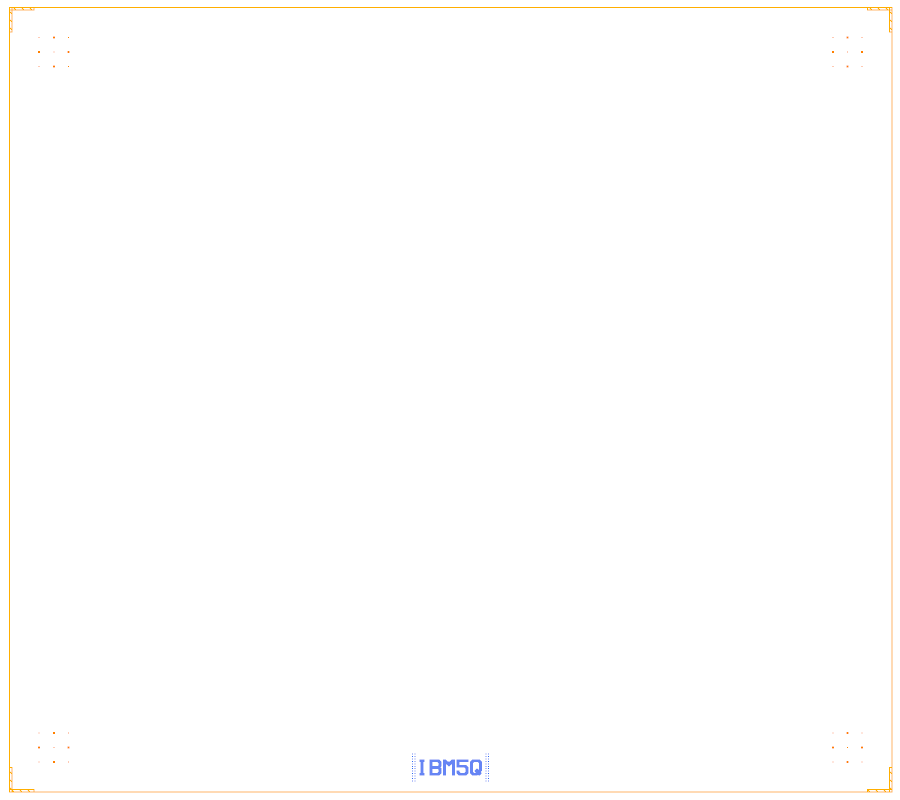

WindowsPath('examples/tutorials/img/t02_die.png')

In [5]:
W, H = 9000, 8000
POCKET = dict(pad_width=750, pad_height=160, pad_gap=20, pocket_width=950, pocket_height=950)  # C_Σ ≈ 130 fF
BUS_PAD, RO_PAD = 150, 140                       # connection-pad widths: bus (sets J), readout (sets χ)
XC, YC = 4500, 4000                              # Q2
DX = 2100                                        # Q2 ↔ the outer qubits in x
YT = YC + 190                                    # the buses run straight at Q2's bus-pad height
STUB = 150                                       # tee → outer qubit stub
L_BUS = {"BusA": 8190, "BusB": 8750}             # λ/2 bus lengths Q2 → tee (set with the LOM for F_BUS)
L_RO = {"Q0": 9420, "Q1": 9494, "Q2": 9562, "Q3": 9348, "Q4": 9420}                   # λ/2 readouts (F_RO)
X = {"Q0": XC - DX, "Q1": XC - DX, "Q2": XC, "Q3": XC + DX, "Q4": XC + DX}
UP = {"Q0": True, "Q1": False, "Q2": False, "Q3": True, "Q4": False}                 # readout pad on the top edge?

d = Designer("t02_ibm_bowtie_5q", box=(0, 0, W, H), chip={"name_chip": "IBM5Q"}, live=LIVE)
T.built(d)
T.snap(d, "die", size=(900, 800), width=360)

## 3 · Pads: five readout pads at the 100 µm rule

One Quantcore `BondPad` per readout line, on the top edge for Q0 and Q3 and on the bottom edge for the others,
`edge="auto"` (outer etch edge 100 µm from the die edge). Next to each, a KQC `FingerCapacitorSquare`: the series
capacitor that terminates the λ/2 readout and sets its κ.

| pad | asked at (x, y) µm | outer etch edge → die edge (µm) |
|---|---|---|
| `P_Q0` | (2400, 6850) | 100.0 |
| `P_Q1` | (2400, 1150) | 100.0 |
| `P_Q2` | (4500, 1150) | 100.0 |
| `P_Q3` | (6600, 6850) | 100.0 |
| `P_Q4` | (6600, 1150) | 100.0 |

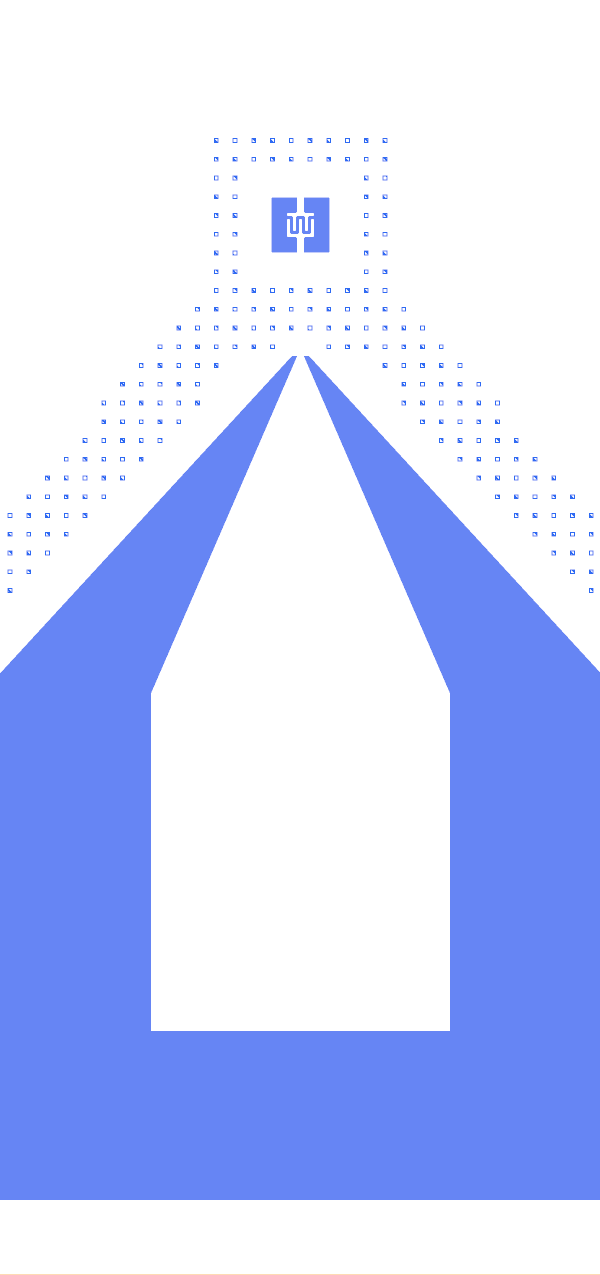

WindowsPath('examples/tutorials/img/t02_pad.png')

In [6]:
pad, cap = {}, {}
with d.batch():
    for n in F_Q:
        y_pad = H - 1150 if UP[n] else 1150
        pad[n] = d.add(f"P_{n}", "BondPad", at=(X[n], y_pad), rot=180 if UP[n] else 0, edge="auto")
        cap[n] = d.add(f"C_{n}", "FingerCapacitorSquare", at=(X[n], y_pad + (-250 if UP[n] else 250)), rot=90)
T.md(T.pad_edges_md(d))
T.snap(d, "pad", box=(XC - 400, 0, XC + 400, 1700), size=(600, 1275), width=280)

## 4 · Components: five pocket transmons and two tees

`TransmonPocket6` is a floating two-pad transmon in a ground pocket: `island1` / `island2` with the trilayer
junction across the 20 µm pad gap. Its *connection pads* are named and placed by `loc_W` / `loc_H` (which corner):
Q2 has two bus pads (`bw`, `be`) and a readout pad `ro`; the outer qubits have `bus` and `ro`. The pad **width** sets
the coupling capacitance: 150 µm on the buses (J), 140 µm on the readouts (χ).

`LineTee` (a Metal T-junction) splits each bus so one λ/2 line reaches two qubits.

<metal:TransmonPocket6 Q2 ports=['be', 'bw', 'ro', 'squid_a', 'squid_b']>
<metal:LineTee TA ports=['prime_end', 'prime_start', 'second_end']>


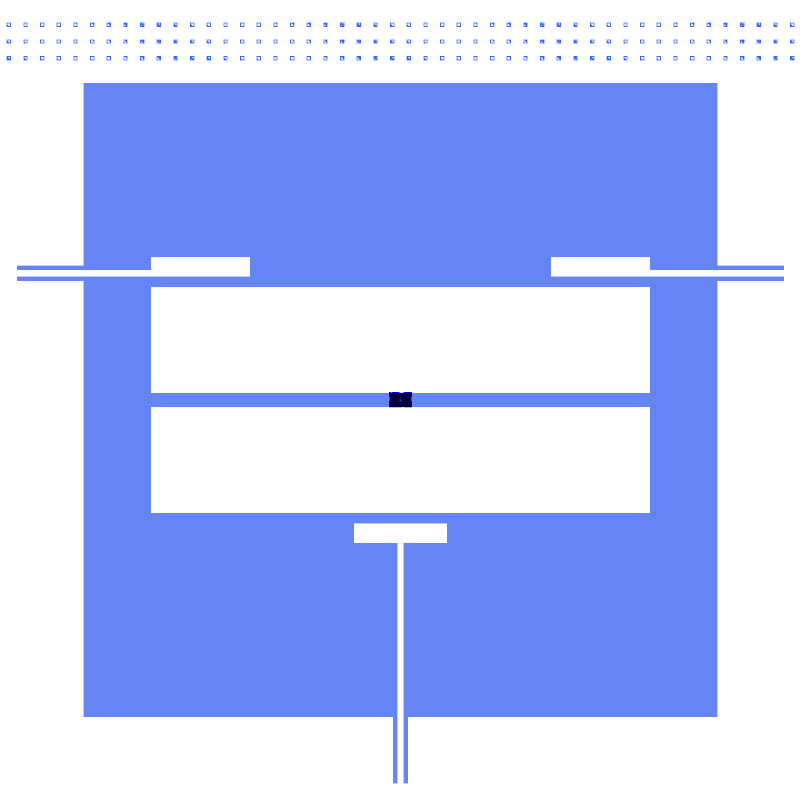

WindowsPath('examples/tutorials/img/t02_qubit.png')

In [7]:
def cpad(name, loc_w, loc_h, width):
    return {name: {"loc_W": loc_w, "loc_H": loc_h, "pad_width": width}}


yo = YT + 50 + STUB + 575                        # outer qubits: their bus pin sits STUB above / below the tee
PLACE = {"Q0": (X["Q0"], yo, {**cpad("bus", 0, -1, BUS_PAD), **cpad("ro", 0, 1, RO_PAD)}),
         "Q1": (X["Q1"], 2 * YT - yo, {**cpad("bus", 0, 1, BUS_PAD), **cpad("ro", 0, -1, RO_PAD)}),
         "Q2": (XC, YC, {**cpad("bw", -1, 1, BUS_PAD), **cpad("be", 1, 1, BUS_PAD), **cpad("ro", 0, -1, RO_PAD)}),
         "Q3": (X["Q3"], yo, {**cpad("bus", 0, -1, BUS_PAD), **cpad("ro", 0, 1, RO_PAD)}),
         "Q4": (X["Q4"], 2 * YT - yo, {**cpad("bus", 0, 1, BUS_PAD), **cpad("ro", 0, -1, RO_PAD)})}
q = {}
with d.batch():
    for name, (x, y, pads_) in PLACE.items():
        params, junction = JUNCTIONS[name]
        q[name] = d.add(name, "metal:TransmonPocket6", at=(x, y), junction=junction, connection_pads=pads_,
                        **POCKET, **params)
    tee = {"A": d.add("TA", "metal:LineTee", at=(XC - DX, YT), rot=90),
           "B": d.add("TB", "metal:LineTee", at=(XC + DX, YT), rot=-90)}
print(q["Q2"])
print(tee["A"])
T.snap(d, "qubit", box=(XC - 600, YC - 600, XC + 600, YC + 600), size=(800, 800), width=360)

## 5 · Routes: two λ/2 buses and five λ/2 readouts

- **Buses:** a meander from Q2's bus pad to the tee's `second_end` (λ/2 for 7.0 / 6.6 GHz, both ends at a voltage
  antinode), then two straight stubs from the tee to the outer qubits' `bus` pads. One waypoint keeps each bus
  meander in the channel between the pockets.
- **Readouts:** a meander from each qubit's `ro` pad to its finger capacitor (λ/2), then a 50 Ω line to the bond
  pad.

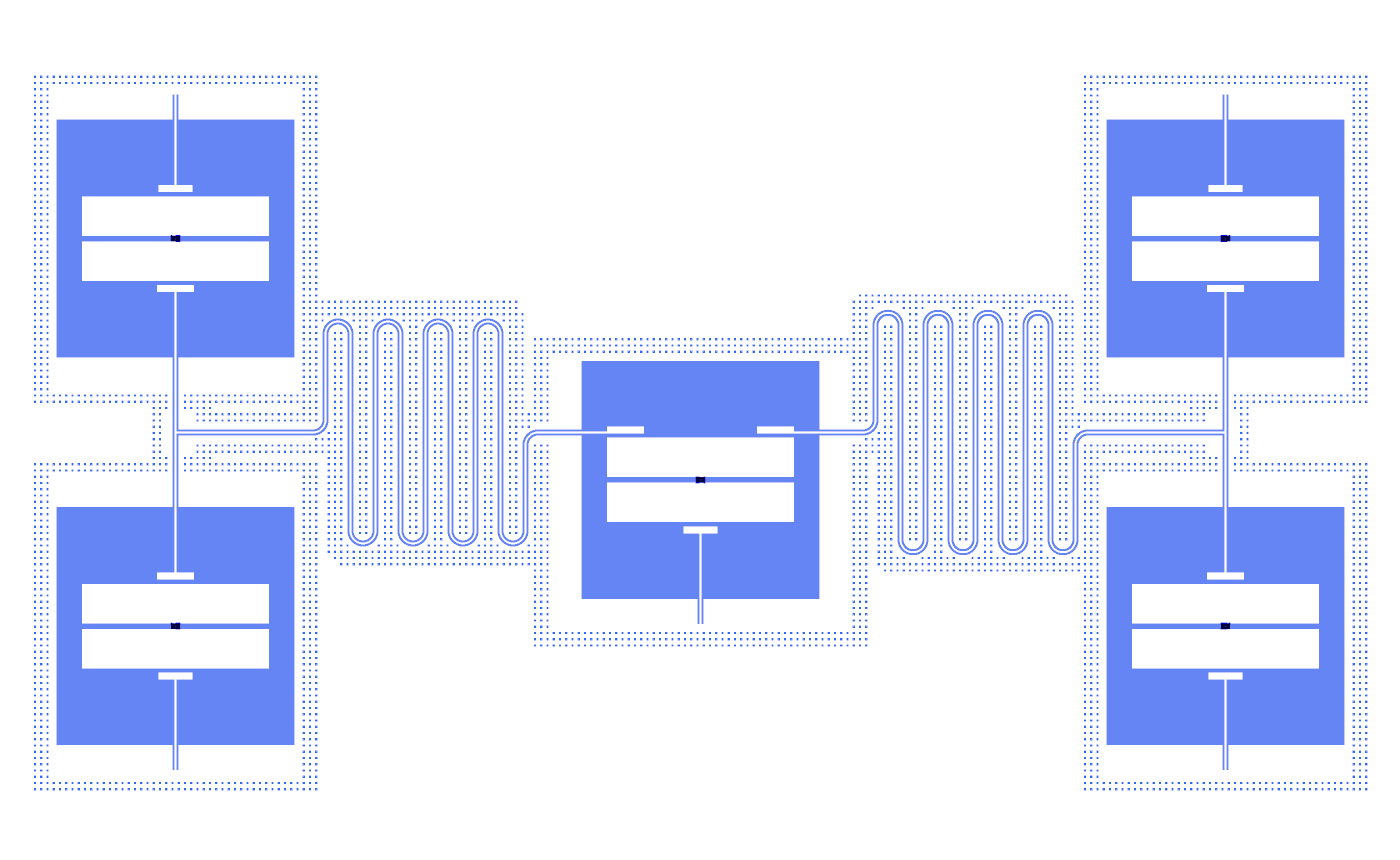

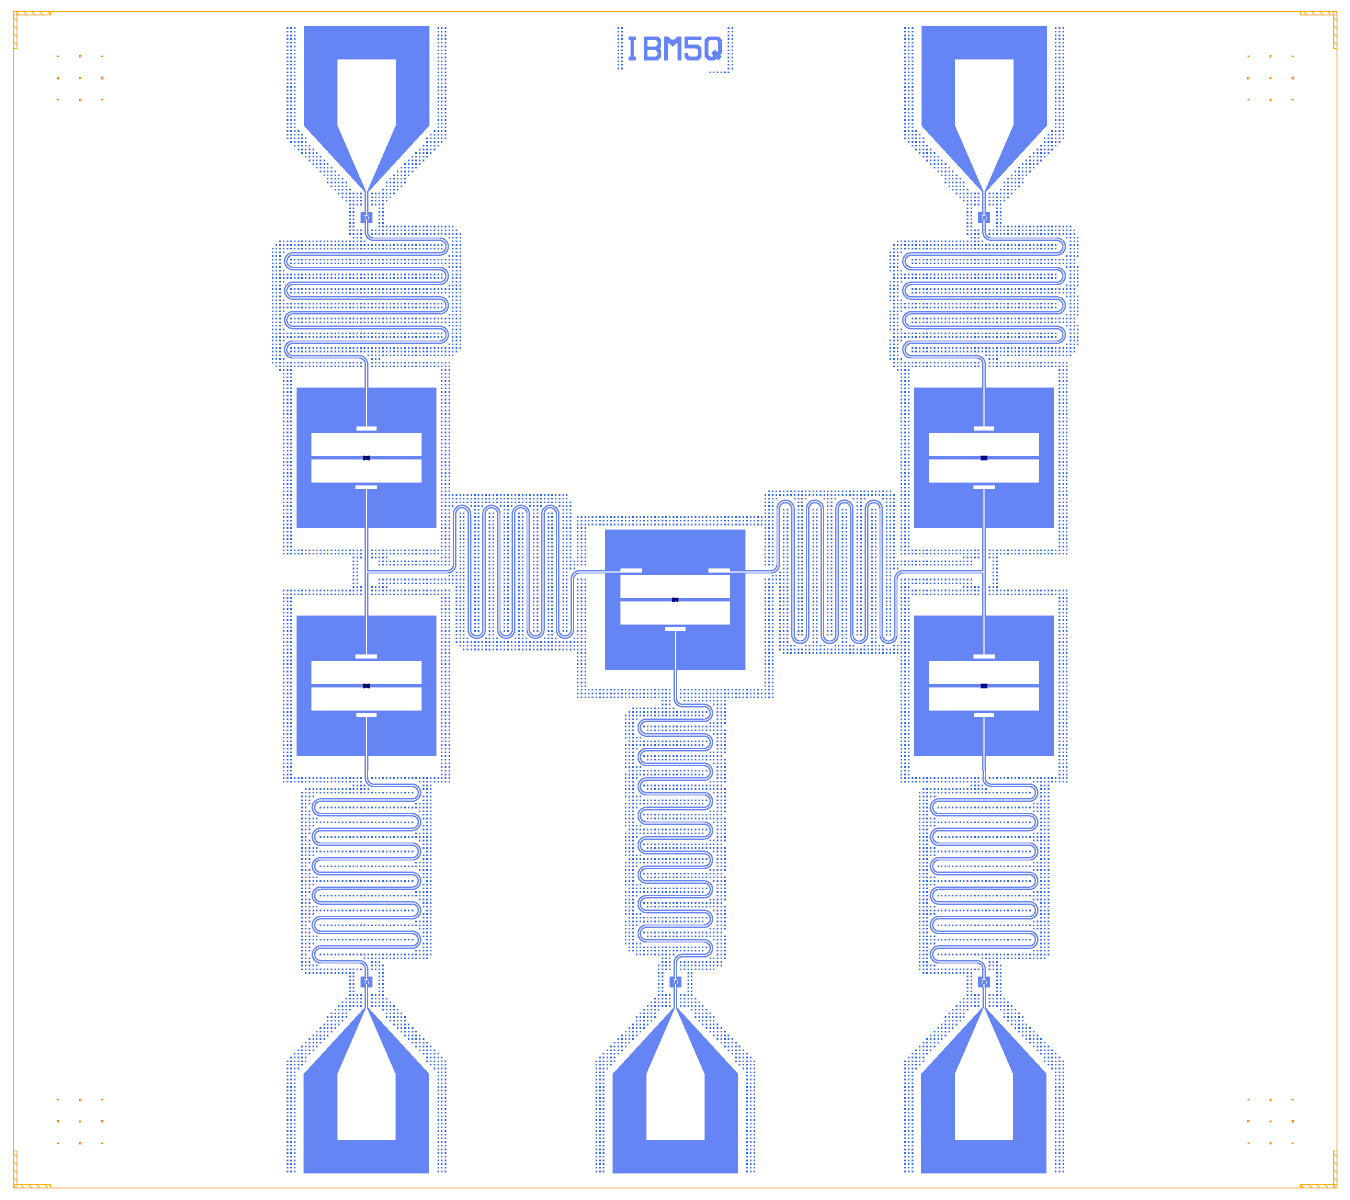

{'BusA': 8190.0, 'BusA_Q0': 150.0, 'BusA_Q1': 150.0, 'BusB': 8750.0, 'BusB_Q3': 150.0, 'BusB_Q4': 150.0, 'R_Q0': 9420.0, 'L_Q0': 138.5, 'R_Q1': 9494.0, 'L_Q1': 138.5, 'R_Q2': 9562.0, 'L_Q2': 138.5, 'R_Q3': 9348.0, 'L_Q3': 138.5, 'R_Q4': 9420.0, 'L_Q4': 138.5}


In [8]:
with d.batch():
    for bus, sx, pin, (top, bot) in (("BusA", -1, "bw", ("Q0", "Q1")), ("BusB", 1, "be", ("Q3", "Q4"))):
        t = tee[bus[-1]]
        xm = XC + sx * (DX - 475 - 50)            # meander between the outer pockets and Q2's pocket
        d.route(bus, q["Q2"][pin], t.second_end, meander=L_BUS[bus], r=50, nodes=[(xm, YT)])
        d.route(f"{bus}_{top}", t.prime_end if sx < 0 else t.prime_start, q[top].bus, r=50)
        d.route(f"{bus}_{bot}", t.prime_start if sx < 0 else t.prime_end, q[bot].bus, r=50)
T.snap(d, "buses", box=(XC - DX - 700, YC - 1100, XC + DX + 700, YC + 1500), size=(1400, 860), width=640)
with d.batch():
    for n in F_Q:
        d.route(f"R_{n}", q[n].ro, cap[n].a if UP[n] else cap[n].b, meander=L_RO[n], r=50)
        d.route(f"L_{n}", cap[n].b if UP[n] else cap[n].a, pad[n].a, r=50)
d.targets(**{n: {"f_q_GHz": F_Q[n], "alpha_MHz": ALPHA[n]} for n in F_Q},
          **{f"R_{n}": {"f_GHz": F_RO[n]} for n in F_Q}, **{b: {"f_GHz": f} for b, f in F_BUS.items()})
T.snap(d, "chip", size=(1350, 1200), width=600)
print({k: round(v, 1) for k, v in T.built(d).route_lengths().items()})

## 6 · DRC

Zero errors. The `dangling_port` warnings are the pockets' `squid_a` / `squid_b`: junction attachment points (the
trilayer junction is drawn by the cell across the pad gap), never route ends. The junctions are inside the R_n
window and every f_q target inside the PDK band, so there are no PDK design warnings.

In [9]:
T.md(T.drc_md(T.drc(d)))
T.md(C.pdk_report(d))

**DRC clean** — 0 errors, 10 warnings, 0 PDK design warnings

| severity | rule | count | example |
|---|---|---|---|
| warning | `dangling_port` | 10 | Q0.squid_a is not connected (no route or snap)<br>Q0.squid_b is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 5 |
| PDK design warnings | 0 (none) |

## 7 · Netlist and LOM

`TransmonPocket6` → two floating pads (`Qn.island1`, `Qn.island2`) with the junction between them, plus a node per
connection pad. Each bus — Q2's pad, the λ/2 `TLres`, the tee and both stubs — joins Q2's bus pad, the tee and both
outer pads into one network (the stubs are wires). Each readout is a λ/2 between the qubit's `ro` pad and the
finger capacitor, whose other side is the 50 Ω pad port. The left triangle:

In [10]:
lb = d.lom()
print(C.lom_summary(lb))
TRI = {"A": ["Q0", "Q1", "Q2", "BusA", "TA", "BusA_Q0", "BusA_Q1"],
       "B": ["Q2", "Q3", "Q4", "BusB", "TB", "BusB_Q3", "BusB_Q4"]}
C.show_netlist(d.lom(select=TRI["A"]))

{'nodes': 22, 'branches': 80, 'controls': 0, 'unconnected': 0}


**12 nodes · 34 branches · 0 controls · 4 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `Q0.island1` | `Q0.island1` |
| `Q0.island2` | `Q0.island2` |
| `Q0.bus` | `Q0.bus`, `Q1.bus`, `Q2.bw`, `TA.t` |
| `Q0.ro` | `Q0.ro` |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.ro` | `Q1.ro` |
| `Q2.island1` | `Q2.island1` |
| `Q2.island2` | `Q2.island2` |
| `Q2.be` | `Q2.be` |
| `Q2.ro` | `Q2.ro` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_Q0_1` | C | `Q0.island1` – `gnd` | 82.8 fF |
| `C_Q0_2` | C | `Q0.island2` – `gnd` | 82.8 fF |
| `C_Q0_12` | C | `Q0.island1` – `Q0.island2` | 75.5 fF |
| `J_Q0` | JJ | `Q0.island1` – `Q0.island2` | Lj 6.12 nH, Cj 16.5 fF |
| `Cg_Q0_bus` | C | `Q0.island2` – `Q0.bus` | 16.9 fF |
| `Cf_Q0_bus` | C | `Q0.island1` – `Q0.bus` | 1.8 fF |
| `Cc_Q0_bus` | C | `Q0.bus` – `gnd` | 31 fF |
| `Cg_Q0_ro` | C | `Q0.island1` – `Q0.ro` | 15.8 fF |
| `Cf_Q0_ro` | C | `Q0.island2` – `Q0.ro` | 1.7 fF |
| `Cc_Q0_ro` | C | `Q0.ro` – `gnd` | 30.5 fF |
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 82.8 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 82.8 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 75.5 fF |
| `J_Q1` | JJ | `Q1.island1` – `Q1.island2` | Lj 6.24 nH, Cj 16.2 fF |
| `Cg_Q1_bus` | C | `Q1.island1` – `Q0.bus` | 16.9 fF |
| `Cf_Q1_bus` | C | `Q1.island2` – `Q0.bus` | 1.8 fF |
| `Cc_Q1_bus` | C | `Q0.bus` – `gnd` | 31 fF |
| `Cg_Q1_ro` | C | `Q1.island2` – `Q1.ro` | 15.8 fF |
| `Cf_Q1_ro` | C | `Q1.island1` – `Q1.ro` | 1.7 fF |
| `Cc_Q1_ro` | C | `Q1.ro` – `gnd` | 30.5 fF |
| `C_Q2_1` | C | `Q2.island1` – `gnd` | 82.8 fF |
| `C_Q2_2` | C | `Q2.island2` – `gnd` | 82.8 fF |
| `C_Q2_12` | C | `Q2.island1` – `Q2.island2` | 75.5 fF |
| `J_Q2` | JJ | `Q2.island1` – `Q2.island2` | Lj 6.6 nH, Cj 15.3 fF |
| `Cg_Q2_bw` | C | `Q2.island1` – `Q0.bus` | 16.9 fF |
| `Cf_Q2_bw` | C | `Q2.island2` – `Q0.bus` | 1.8 fF |
| `Cc_Q2_bw` | C | `Q0.bus` – `gnd` | 31 fF |
| `Cg_Q2_be` | C | `Q2.island1` – `Q2.be` | 16.9 fF |
| `Cf_Q2_be` | C | `Q2.island2` – `Q2.be` | 1.8 fF |
| `Cc_Q2_be` | C | `Q2.be` – `gnd` | 31 fF |
| `Cg_Q2_ro` | C | `Q2.island2` – `Q2.ro` | 15.8 fF |
| `Cf_Q2_ro` | C | `Q2.island1` – `Q2.ro` | 1.7 fF |
| `Cc_Q2_ro` | C | `Q2.ro` – `gnd` | 30.5 fF |
| `BusA` | TLres | `Q0.bus` – `gnd` | lambda/2, 8190 µm, 7.694 GHz |

**Unconnected ports:** `Q0.ro`, `Q1.ro`, `Q2.be`, `Q2.ro`

## 8 · LOM simulation against IBM's values

**(a) Each qubit with its readout chain** (λ/2, finger capacitor, pad line, 50 Ω port): QuTiP dressed values,
IBM's in brackets. f_q and f_r land on the targets; α is ≈ −145 MHz instead of −330 MHz, the price of the PDK's
R_n window (smaller L_J → larger C_Σ at the same f_q → smaller |α| ≈ E_C).

In [11]:
read = {f"{n}+R": [n, f"R_{n}", f"C_{n}", f"L_{n}", f"P_{n}"] for n in F_Q}
results = C.simulate_groups(d, read)
T.md(C.groups_md(results, d.data["targets"]))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q0+R | Q0 | 5.2684 (5.2823) | -145.1 (-330.8) | R_Q0 | 6.429 (6.5304) | 0.908 | -0.888 |
| Q1+R | Q1 | 5.2244 (5.2475) | -145.5 (-330.4) | R_Q1 | 6.3808 (6.4817) | 0.888 | -0.878 |
| Q2+R | Q2 | 5.028 (5.0334) | -143.2 (-376.1) | R_Q2 | 6.3367 (6.4365) | 0.871 | -0.737 |
| Q3+R | Q3 | 5.2685 (5.292) | -145.2 (-329.7) | R_Q3 | 6.4765 (6.5789) | 0.929 | -0.841 |
| Q4+R | Q4 | 5.0893 (5.0785) | -147 (-333.1) | R_Q4 | 6.4285 (6.5301) | 0.909 | -0.687 |

**(b) The buses and J.** Each triangle (three qubits, the bus, the tee and the stubs) as one circuit: the bus mode
and the three qubits. J of a pair is half the minimum splitting at the avoided crossing, found by sweeping the second
qubit's L_J through the first's frequency (`C.exchange_coupling`, ≈ 10 s per pair through Q2). The two outer pairs
(Q0–Q1, Q3–Q4) need the whole triangle (≈ 2 min each): set `ALL_PAIRS = True` to include them.

In [12]:
buses = C.simulate_groups(d, {f"triangle {k}": sel for k, sel in TRI.items()}, max_modes=4)
for g, res in buses.items():
    T.md(f"**{g}** (bus target {F_BUS['BusA' if g.endswith('A') else 'BusB']} GHz):\n\n" + C.modes_md(res))
ALL_PAIRS = False
PAIRS = {"Q0-Q2": ["Q0", "Q2", "BusA", "TA", "BusA_Q0"], "Q1-Q2": ["Q1", "Q2", "BusA", "TA", "BusA_Q1"],
         "Q2-Q3": ["Q2", "Q3", "BusB", "TB", "BusB_Q3"], "Q2-Q4": ["Q2", "Q4", "BusB", "TB", "BusB_Q4"]}
if ALL_PAIRS:
    PAIRS.update({"Q0-Q1": TRI["A"], "Q3-Q4": TRI["B"]})
J = {p: C.exchange_coupling(d, sel, *p.split("-")) for p, sel in PAIRS.items()}
T.md(C.exchange_md(J, J_SRC))

**triangle A** (bus target 7.0 GHz):

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q2 | qubit | 5.1700 | 0 | 134.6 | J_Q2 1.00 |
| Q1 | qubit | 5.3641 | 0 | 135.9 | J_Q1 1.00 |
| Q0 | qubit | 5.4079 | 0 | 135.7 | J_Q0 1.00 |
| BusA | resonator | 6.9110 | 0 | 0.0 | BusA 0.99 |

**triangle B** (bus target 6.6 GHz):

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q2 | qubit | 5.1696 | 0 | 134.0 | J_Q2 1.00 |
| Q4 | qubit | 5.2295 | 0 | 137.1 | J_Q4 1.00 |
| Q3 | qubit | 5.4071 | 0 | 135.9 | J_Q3 1.00 |
| BusB | resonator | 6.5112 | 0 | 0.0 | BusB 0.99 |

| pair | f_a (GHz) | f_b (GHz) | J (MHz) | target J (MHz) | ZZ (kHz) |
|---|---|---|---|---|---|
| Q0-Q2 | 5.2675 | 5.0315 | 1.61 | 1.82 | -30 |
| Q1-Q2 | 5.2235 | 5.0315 | 1.55 | 1.24 | -63.1 |
| Q2-Q3 | 5.0312 | 5.2670 | 1.56 | 1.82 | -45.9 |
| Q2-Q4 | 5.0312 | 5.0879 | 1.57 | 1.81 | 69.6 |

> **Simulation PC (32 GB+ RAM).** The cells below solve the FEM jobs of the bowtie (the whole-chip Q3D C-matrix, the qubit-only eigenmodes, the readout boxes and the render check) in AEDT; the whole-chip eigenmode and driven runs (`WHOLE_ANALYSES`) take hours and more than 30 GB. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

J comes out at IBM's 1.2–2.0 MHz scale. The static ZZ (last column) is the residual always-on interaction at the
design frequencies; the cross-resonance gate works on the detuned pairs. The values of sections 8 (a) and (b) are
**component estimates** (the LOM on each component's own estimate, circuit by circuit: QuCat's normal-mode solve of
all five qubits and seven resonators at once takes more than 10 min here); section 10 fills the simulated ones from the FEM.

## 9 · FEM stage 1: the subset FEM and its check

| group | analysis | gives |
|---|---|---|
| the `SIM_SUBSET` boxes (`SUB`, or `SUB_<qubits>` for several boxes) | `q3d_cmatrix` | each chosen qubit with its readout chain: its pads, its readout coupling, its bus pads, the finger capacitor to the feedline |
| the same qubits alone (`SUBQ…`, `readouts=False`) | `eigenmode_epr` | the qubit mode: f, Q, p_J (the readout leaves the box as a 50 Ω line: a box with the 9.5 mm λ/2 needs > 11 GB of RAM here) |
| `triangle_A`, `triangle_B` | `q3d_cmatrix` | every bus pad's C to both qubit pads, the stubs and the tee (exported, too large to solve here) |
| `Q2_read` | `q3d_cmatrix` | rendered into AEDT below (no solve) to check the geometry |

`RUN_FEM = True` solves the `SIM_SUBSET` jobs with `hfss.solve_job` (one AEDT at a time; with less than
`T.MIN_FREE_GB` of RAM free it prints a note and solves anyway). The results are kept under `examples/tutorials/fem/`
and read back from there later. A box's kept results stay valid when you add or change *another* subset (each job
records its own group's hash). `T.subset_check` then shows the FEM values only; section 10 fills them into the whole netlist.

**`AEDT_MODE`**: `"batch"` solves in a new non-graphical AEDT; `"gui"` opens a new AEDT window and leaves it open, so you watch the mesh, the convergence and the fields; `"attach"` runs inside the AEDT window you already have open (or opens one) and leaves the project there. Every mode prints a progress line (step, pass, mesh, ΔF / ΔS / ΔC) every 30 s, so a stuck run is visible; on a timeout only what qcc started is stopped.

**`FEM_FAST`**: every job is exported with the library's fast test settings (`sim_tools.export.FAST_SETTINGS`: Q3D 2 % / ≤ 8 passes, eigenmode ΔF 1 % / ≤ 3 passes (memory-bound here), driven ΔS 0.05 / ≤ 6 passes, mesh seeds × 3 (none given: a 40 / 30 µm gap seed for eigenmode / driven), sweeps ≤ 10 001 points), so the whole chain (solve → keep → bring back → feedback) runs in minutes. The values are not converged; they move with the design. `False` exports the settings as written for a production run (kept results of a full solve also stand in for a fast re-run of the same design).

In [13]:
FEM_FAST = T.fem_fast(FEM_FAST)                   # the switch from the top: fast test settings, or as below
d.sim_group("triangle_A", TRI["A"], margin_um=100, analyses=["q3d_cmatrix"])
d.sim_group("triangle_B", TRI["B"], margin_um=100, analyses=["q3d_cmatrix"])
d.sim_group("Q2_read", ["Q2", "R_Q2", "C_Q2"], margin_um=100, analyses=["q3d_cmatrix", "eigenmode_epr"])
# SIM_SUBSET → sim groups. Q3D: each qubit with its readout chain (box SUB / SUB_<qubits>). Eigenmode: the qubit alone
# (SUBQ…: its λ/2 readout and the buses are cut by the box / at the pads; a 9.5 mm λ/2 in an eigenmode box needs
# > 11 GB here). ≤ 2 passes, 10 % refinement: pass 2 at 30 % (108 k tets) took > 12 GB on this workstation.
SUB, SUBQ, PLAN = [], [], {}
if SIM_SUBSET:
    SUB = T.sim_subset(d, SIM_SUBSET, name="SUB", margin_um=100, analyses=["q3d_cmatrix"])
    PLAN = {g.name: g for g in getattr(d, "subset_plan", [])}
    if "eigenmode_epr" in SUBSET_ANALYSES:
        SUBQ = T.sim_subset(d, SIM_SUBSET, name="SUBQ", margin_um=100, analyses=["eigenmode_epr"], readouts=False,
                            settings={"eigenmode_epr": {"n_modes": 3, "min_frequency": 3.0, "maximum_passes": 2,
                                                        "percent_refinement": 10}}, show=False)
        PLAN.update({g.name: g for g in d.subset_plan})
DESIGN = d.save(T.DESIGNS / "t02_ibm_bowtie_5q.json")
jobs = C.export_sims(DESIGN, ["triangle_A", "triangle_B", "Q2_read"], "q3d_cmatrix")
sub_jobs = {"q3d_cmatrix": C.export_sims(DESIGN, SUB, "q3d_cmatrix")} if SUB else {}
if SUBQ:
    sub_jobs["eigenmode_epr"] = C.export_sims(DESIGN, SUBQ, "eigenmode_epr")
T.md(C.jobs_md(jobs) + "\n" + "\n".join(C.jobs_md(j).split("\n", 2)[2] for j in sub_jobs.values()))
keeps = {(g, a): T.solve_or_load(job[0], RUN_FEM, force=RESOLVE, aedt=AEDT_MODE, timeout=2400)
         for a, js in sub_jobs.items() for g, job in js.items()}   # one AEDT at a time
# the check: convergence, raw C-matrix / eigenmodes, the FEM-filled capacitances next to the estimates (FEM only)
CHECK = T.subset_check({f"{g} · {a}": k for (g, a), k in keeps.items()}, d.lom().model, DESIGN)

FEM_FAST: jobs are exported with the fast test settings (q3d_cmatrix percent_error 2, maximum_passes 8, minimum_passes 1; hfss_driven max_delta_s 0.05, maximum_passes 6, minimum_passes 1; eigenmode_epr max_delta_f 1, maximum_passes 3, minimum_passes 1); values are not converged


**SIM_SUBSET = [('Q2', None)]** → 1 box(es); each is rendered and simulated on its own, and its values fill only these components of the whole-chip netlist:

| group (box) | qubits | readout chain | buses in | buses cut at the qubit | feedline (cut by the box) |
|---|---|---|---|---|---|
| `SUB` | Q2 | Q2: R_Q2, C_Q2 | – | BusA, BusB | L_Q2 |

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| triangle_A | `build/jobs/t02_ibm_bowtie_5q_triangle_A_q3d_cmatrix` | 1 · junction · `Q0.junction`<br>2 · junction · `Q1.junction`<br>3 · junction · `Q2.junction`<br>4 · waveguide · `Q2.bw`<br>5 · waveguide · `TA.second_end`<br>6 · waveguide · `TA.prime_end`<br>7 · waveguide · `Q0.bus`<br>8 · waveguide · `TA.prime_start`<br>9 · waveguide · `Q1.bus`<br>10 · edge · `BusB`<br>11 · edge · `R_Q0`<br>12 · edge · `R_Q1`<br>13 · edge · `R_Q2` | `Q0.island2`, `Q1.island2`, `Q2.island2`, `Q2.bw`, `TA.second_end`, `TA.prime_end`, `TA.prime_start`, `BusB`, `R_Q0`, `R_Q1`, `R_Q2`, `Q1.island1`, `Q2.island1`, `Q0.island1` |
| triangle_B | `build/jobs/t02_ibm_bowtie_5q_triangle_B_q3d_cmatrix` | 1 · junction · `Q2.junction`<br>2 · junction · `Q3.junction`<br>3 · junction · `Q4.junction`<br>4 · waveguide · `Q2.be`<br>5 · waveguide · `TB.second_end`<br>6 · waveguide · `TB.prime_start`<br>7 · waveguide · `Q3.bus`<br>8 · waveguide · `TB.prime_end`<br>9 · waveguide · `Q4.bus`<br>10 · edge · `BusA`<br>11 · edge · `R_Q2`<br>12 · edge · `R_Q3`<br>13 · edge · `R_Q4` | `Q2.island2`, `Q3.island2`, `Q4.island2`, `Q2.be`, `TB.second_end`, `TB.prime_start`, `TB.prime_end`, `BusA`, `R_Q2`, `R_Q3`, `R_Q4`, `Q4.island1`, `Q2.island1`, `Q3.island1` |
| Q2_read | `build/jobs/t02_ibm_bowtie_5q_Q2_read_q3d_cmatrix` | 1 · junction · `Q2.junction`<br>2 · waveguide · `Q2.ro`<br>3 · waveguide · `C_Q2.b`<br>4 · edge · `BusA`<br>5 · edge · `BusB`<br>6 · edge · `L_Q2` | `Q2.island2`, `Q2.ro`, `C_Q2.b`, `BusA`, `BusB`, `L_Q2`, `Q2.island1` |
| SUB | `build/jobs/t02_ibm_bowtie_5q_SUB_q3d_cmatrix` | 1 · junction · `Q2.junction`<br>2 · waveguide · `Q2.bw`<br>3 · waveguide · `Q2.be`<br>4 · waveguide · `Q2.ro`<br>5 · waveguide · `C_Q2.b`<br>6 · edge · `L_Q2` | `Q2.island2`, `Q2.bw`, `Q2.be`, `Q2.ro`, `C_Q2.b`, `L_Q2`, `Q2.island1` |
| SUBQ | `build/jobs/t02_ibm_bowtie_5q_SUBQ_eigenmode_epr` | 1 · junction · `Q2.junction`<br>2 · edge_lumped · `R_Q2` | `Q2.island2`, `R_Q2`, `Q2.island1` |

| analysis | passes | tets (last) | criterion | last Δ / target | converged | wall time (s) |
|---|---|---|---|---|---|---|
| SUB · q3d_cmatrix | 7 | 7050 | Delta % | 1.99 / 2.0 | False | 54.6 |
| SUBQ · eigenmode_epr | 2 | 91000 | Max Delta Freq. % | 1.41 / 1.0 | False | 218.3 |

Q3D C-matrix of `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` (2024.1.0, 54.6 s; Maxwell form, fF):

| net | `Q2.island2` | `Q2.bw` | `Q2.be` | `Q2.ro` | `C_Q2.b` | `L_Q2` | `Q2.island1` |
|---|---|---|---|---|---|---|---|
| `Q2.island2` | 68.647 | -1.416 | -1.418 | -17.657 | -0.002 | -0.002 | -66.144 |
| `Q2.bw` | -1.416 | 39.374 | -0.109 | -0.121 | -0.000 | -0.000 | -14.713 |
| `Q2.be` | -1.418 | -0.109 | 39.041 | -0.121 | -0.000 | -0.000 | -14.674 |
| `Q2.ro` | -17.657 | -0.121 | -0.121 | 43.338 | -0.000 | -0.001 | -1.815 |
| `C_Q2.b` | -0.002 | -0.000 | -0.000 | -0.000 | 18.951 | -5.407 | -0.001 |
| `L_Q2` | -0.002 | -0.000 | -0.000 | -0.001 | -5.407 | 19.744 | -0.002 |
| `Q2.island1` | -66.144 | -14.713 | -14.674 | -1.815 | -0.001 | -0.002 | 62.627 |

Eigenmodes of `t02_ibm_bowtie_5q_SUBQ_eigenmode_epr` (2024.1.0, 218.3 s):

| mode | f linear (GHz) | Q | p_J | f dressed, pyEPR (GHz) | self-Kerr χ_mm (MHz) |
|---|---|---|---|---|---|
| 1 | 5.2364 | 936.1 | 0.9923 | 5.0963 | -145.3 |
| 2 | 15.5419 | 2.822e+07 | 0.0000 | 15.5419 | 0.0 |
| 3 | 15.6371 | 1.687e+06 | 0.0000 | 15.6371 | 0.0 |

Cross-Kerr (dispersive shift) χ₁₂ = 0.000 MHz (pyEPR, numerical diagonalisation).

Convergence: 2 passes, 91000 tets, last Max Delta Freq. % 1.4128 (target 1.0), converged: False.

**FEM-filled capacitances of the simulated components** (the other branches keep their estimates):

| branch | nodes | estimate | FEM | from |
|---|---|---|---|---|
| `C_C_Q2` | C_Q2.a – C_Q2.b | 7.18 | 5.407 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `C_C_Q2_b` | C_Q2.b – gnd | 3.5 | 0.8624 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `C_Q2_12` | Q2.island1 – Q2.island2 | 75.5 | 66.14 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cg_Q2_bw` | Q2.island1 – Q0.bus | 16.9 | 14.71 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cf_Q2_bw` | Q2.island2 – Q0.bus | 1.8 | 1.416 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cc_Q2_bw` | Q0.bus – gnd | 31 | 8.62 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cg_Q2_be` | Q2.island1 – Q2.be | 16.9 | 14.67 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cf_Q2_be` | Q2.island2 – Q2.be | 1.8 | 1.418 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cc_Q2_be` | Q2.be – gnd | 31 | 8.325 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cg_Q2_ro` | Q2.island2 – C_Q2.b | 15.8 | 17.66 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cf_Q2_ro` | Q2.island1 – C_Q2.b | 1.7 | 1.816 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cc_Q2_ro` | C_Q2.b – gnd | 30.5 | 7.515 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |

**12** branches filled from FEM; **51** kept their estimates (48 outside the subset, e.g. `C_C_Q0`, `C_C_Q0_a`, `C_C_Q0_b`, `C_C_Q1`, `C_C_Q1_a`, `C_C_Q1_b`).
- `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` (group `SUB`, q3d_cmatrix): 12 branches; scope C_Q2, Q2, R_Q2

**Look at these before the whole chip:** if the passes converged (or Δ sits near its target), the capacitances are positive and near their estimates and the qubit mode has p_J ≈ 1, go on and render and simulate the whole chip (stage 2). If not, change the mesh / settings here first: a subset solves in minutes.

**Render: does the geometry reach AEDT?** `hfss.render(design, group, analysis, solve=False)` builds the cut-out,
exports the KQC job and runs one batch AEDT that imports the geometry, assigns the materials, the thin-conductor
sheets, the nets and the setup, and saves the `.aedt` project — no mesh, no solve (≈ 30 s). `hfss.check_project`
then reads the saved project back: design and solution type, the sapphire stack, every metal sheet, every net
named after its LOM node (`Q2.*`, the bus pads), every solver setting. The check is kept in
`examples/tutorials/fem/t02_ibm_bowtie_5q_Q2_read_q3d_cmatrix/check.json`.

In [14]:
rendered = T.render_or_load(DESIGN, "Q2_read", "q3d_cmatrix", RUN_FEM, aedt=AEDT_MODE)   # RUN_FEM: render now; else the kept check
if rendered:
    T.md(T.check_md(rendered))

`t02_ibm_bowtie_5q_Q2_read_q3d_cmatrix`: Q3D Extractor / None, rendered in 16.0 s; 10 boundaries, nets ['Net1', 'Net2', 'Net3', 'Net4', 'Net5', 'Net6', 'Net7'] — **OK**

| check | ok | detail |
|---|---|---|
| design type | ✓ | Q3D Extractor / None |
| substrate_1 stack | ✓ | sapphire εr 10.25, 650 µm (PDK 10.25, 650 µm) |
| metal sheets ThinConductor | ✓ | 9/9 sheets |
| net Net1 = Q2.island2 | ✓ | objects ['1t1_signal_1_5'] |
| net Net2 = Q2.ro | ✓ | objects ['1t1_signal_2_6'] |
| net Net3 = C_Q2.b | ✓ | objects ['1t1_signal_3_7'] |
| net Net4 = BusA | ✓ | objects ['1t1_signal_4_4'] |
| net Net5 = BusB | ✓ | objects ['1t1_signal_5_3'] |
| net Net6 = L_Q2 | ✓ | objects ['1t1_signal_6_1'] |
| net Net7 = Q2.island1 | ✓ | objects ['1t1_signal_7_2'] |
| no unlabelled signal nets | ✓ |  |
| settings read back | ✓ | 4 keys |

> **Simulation PC (32 GB+ RAM).** The cells below fill the 12-branch whole netlist from the solved jobs and simulate it circuit by circuit (all five qubits and seven resonators at once takes more than 10 min); the LOM vs FEM comparison needs fresh converged FEM results. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

## 10 · FEM stage 2: the subset values in the whole LOM

**The whole-chip FEM is opt-in (`FEM_WHOLE = True`; slow).** The built-in group `chip` holds every instance and
route; nothing is cut, and each bond pad gets a 50 Ω port. `WHOLE_ANALYSES` chooses what is solved then:

| analysis | what it gives | on this workstation (FEM_FAST, 31 GB RAM) |
|---|---|---|
| `q3d_cmatrix` | every pad, bus and readout in one C-matrix → fills every branch | ≈ 3 min, a few GB (180 s on 2026-11-14) |
| `eigenmode_epr` | the 12 modes (5 qubits, 5 readouts, 2 buses), p_J, pyEPR | not run here: several 10⁵–10⁶ tets at pass 1 (one 9.5 mm λ/2 box alone took 197 k tets and 10.8 GB); expect > 30 GB (swapping) and hours |
| `hfss_driven` | S-parameters between the five pads over 6.2–7.2 GHz | as the eigenmode |

With `FEM_WHOLE = False` (the default) nothing is solved here: stage 2 uses the stage-1 subset jobs.

In [15]:
from quantcore_circuits.sim_tools import build_simulation, export_job

# solver settings of the whole-chip jobs (on top of FEM_FAST): the eigenmode needs a slot per mode (5 qubits,
# 5 readouts, 2 buses); the driven run sweeps the readout band (the pads are 50 Ω lumped ports)
WHOLE_SETTINGS = {"q3d_cmatrix": {}, "eigenmode_epr": {"n_modes": 12, "min_frequency": 4.5},
                  "hfss_driven": {"frequency": 6.5, "sweep_start": 6.2, "sweep_end": 7.2, "sweep_count": 10001,
                                  "sweep_type": "fast"}}
WHOLE_TIMEOUT = {"q3d_cmatrix": 2400, "eigenmode_epr": 8 * 3600, "hfss_driven": 8 * 3600}   # s


def send_whole(a):
    """Export the whole chip (built-in group "chip") for analysis ``a`` → build/jobs/t02_ibm_bowtie_5q_chip_<a>."""
    setup = build_simulation(DESIGN, "chip", a)
    return export_job(setup, f"build/jobs/{d.design.name}_chip_{a}", overwrite=True, **WHOLE_SETTINGS[a])


wkeep = ({a: T.solve_or_load(send_whole(a), RUN_FEM, force=RESOLVE, aedt=AEDT_MODE, timeout=WHOLE_TIMEOUT[a])
          for a in WHOLE_ANALYSES} if FEM_WHOLE else {})
if wkeep:
    T.md(T.convergence_md({f"chip · {a}": k for a, k in wkeep.items()}))
# the jobs that fill the whole netlist: the whole chip with FEM_WHOLE, else the stage-1 subset jobs
FILL_Q3D = ([wkeep["q3d_cmatrix"]] if wkeep.get("q3d_cmatrix") else
            [k for (g, a), k in keeps.items() if a == "q3d_cmatrix" and k])
FILL_EIG = ({"chip": wkeep["eigenmode_epr"]} if wkeep.get("eigenmode_epr") else
            {g: k for (g, a), k in keeps.items() if a == "eigenmode_epr" and k})
FROM = "whole-chip" if wkeep.get("q3d_cmatrix") else "subset"
print(f"stage 2 fills the whole netlist from the {FROM} job(s):", [k.name for k in FILL_Q3D] or "none (estimates)")
if wkeep.get("q3d_cmatrix"):
    T.md(T.cmatrix_md(wkeep["q3d_cmatrix"]).split("\n")[0] + " the full matrix is in its `results/results.json`.")
if wkeep.get("eigenmode_epr"):
    T.md(T.eigen_md(wkeep["eigenmode_epr"]))
if wkeep.get("hfss_driven"):
    T.md(T.driven_md(wkeep["hfss_driven"]))

stage 2 fills the whole netlist from the subset job(s): ['t02_ibm_bowtie_5q_SUB_q3d_cmatrix']


**(a) The whole netlist, filled, and LOM vs FEM.** `fill(d.lom().model, DESIGN, FILL_Q3D)` fills the branches the
jobs simulated (with the subset default: Q2's pads, its readout coupling, its bus pads, the finger capacitor);
every other branch keeps its component estimate and says so (`scope="auto"`; with `FEM_WHOLE` every branch is
filled). The LOM then runs on that **whole** netlist. QuCat's normal-mode solve of all five qubits and seven
resonators at once takes more than 10 min here, so the filled netlist is simulated circuit by circuit, every component
in one: each qubit's readout circuit (f_q, α, f_r, χ) and each bus triangle (the bus mode) — the circuits of section 8,
now on the filled values. `loop.analyse` runs the estimators on every qubit–readout pair of the same netlist and puts
the whole chip on the dashboard (`build/t02/state.json`). The eigenmode / pyEPR values of the simulated qubits are the
FEM column of the comparison.

In [16]:
from quantcore_circuits import loop
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

ON_FEM, rows = {}, []
filled_w = fill(d.lom().model, DESIGN, FILL_Q3D)   # the whole chip's netlist; unsimulated branches keep estimates
T.md(T.subset_md(filled_w, rows=16))
SIMULATED = list(F_Q) if FROM == "whole-chip" else [q for g in SUB for q in PLAN[g].qubits]
for n in F_Q:                                      # each readout circuit of the filled whole netlist
    a = results[f"{n}+R"].params                   # the component estimates (section 8)
    b = ON_FEM[n] = simulate(fill(d.lom(select=read[f"{n}+R"]).model, DESIGN, FILL_Q3D), max_modes=2).params
    src = f"LOM on {FROM} Q3D" if n in SIMULATED else "estimate (not simulated)"
    rows += [(f"{n} f_q (GHz)", a.get(f"{n}.f_q_GHz"), b.get(f"{n}.f_q_GHz"), f"IBM {F_Q[n]}; {src}"),
             (f"{n} α (MHz)", a.get(f"{n}.alpha_MHz"), b.get(f"{n}.alpha_MHz"), src),
             (f"R_{n} f_r (GHz)", a.get(f"R_{n}.f_GHz"), b.get(f"R_{n}.f_GHz"), f"IBM {F_RO[n]}; {src}"),
             (f"R_{n} χ (MHz)", a.get(f"R_{n}.chi_MHz"), b.get(f"R_{n}.chi_MHz"), src)]
for k, sel in TRI.items():                         # each bus triangle: the bus mode
    bus = f"Bus{k}"
    b = ON_FEM[bus] = simulate(fill(d.lom(select=sel).model, DESIGN, FILL_Q3D), max_modes=4).params
    rows.append((f"{bus} f (GHz)", buses[f"triangle {k}"].params.get(f"{bus}.f_GHz"), b.get(f"{bus}.f_GHz"),
                 f"target {F_BUS[bus]}; LOM on the filled netlist"))
for g, k in FILL_EIG.items():                      # the eigenmode jobs: FEM f_q, α of the qubits they hold
    qs = list(F_Q) if g == "chip" else PLAN[g].qubits
    ev = T.epr_values(k, {q: f"R_{q}" for q in qs}, {f"R_{q}": ON_FEM[q].get(f"R_{q}.f_GHz", F_RO[q]) for q in qs})
    for q in qs:
        if f"{q}.f_q_GHz" in ev:
            rows += [(f"{q} f_q (GHz), FEM", ON_FEM[q].get(f"{q}.f_q_GHz"), ev[f"{q}.f_q_GHz"],
                      f"LOM on the filled netlist vs pyEPR ({k.name})"),
                     (f"{q} α (MHz), FEM", ON_FEM[q].get(f"{q}.alpha_MHz"), ev.get(f"{q}.alpha_MHz"),
                      f"LOM on the filled netlist vs pyEPR ({k.name})")]
        elif f"{q}.f_linear_GHz" in ev:
            rows.append((f"{q} f_q (GHz), FEM", ON_FEM[q].get(f"{q}.f_q_GHz"), ev[f"{q}.f_linear_GHz"],
                         f"linear eigenfrequency (pyEPR left out at this mesh), {k.name}"))
T.md(T.fem_vs_lom_md(rows))
an = loop.analyse(DESIGN, FILL_Q3D + list(FILL_EIG.values()))   # estimators on every pair → dashboard
print("consensus on the whole netlist:", an.goal.get("summary"))

| branch | nodes | estimate | FEM | from |
|---|---|---|---|---|
| `C_C_Q2` | C_Q2.a – C_Q2.b | 7.18 | 5.407 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `C_C_Q2_b` | C_Q2.b – gnd | 3.5 | 0.8624 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `C_Q2_12` | Q2.island1 – Q2.island2 | 75.5 | 66.14 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cg_Q2_bw` | Q2.island1 – Q0.bus | 16.9 | 14.71 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cf_Q2_bw` | Q2.island2 – Q0.bus | 1.8 | 1.416 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cc_Q2_bw` | Q0.bus – gnd | 31 | 8.62 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cg_Q2_be` | Q2.island1 – Q2.be | 16.9 | 14.67 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cf_Q2_be` | Q2.island2 – Q2.be | 1.8 | 1.418 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cc_Q2_be` | Q2.be – gnd | 31 | 8.325 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cg_Q2_ro` | Q2.island2 – C_Q2.b | 15.8 | 17.66 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cf_Q2_ro` | Q2.island1 – C_Q2.b | 1.7 | 1.816 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |
| `Cc_Q2_ro` | C_Q2.b – gnd | 30.5 | 7.515 | `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` |

**12** branches filled from FEM; **51** kept their estimates (48 outside the subset, e.g. `C_C_Q0`, `C_C_Q0_a`, `C_C_Q0_b`, `C_C_Q1`, `C_C_Q1_a`, `C_C_Q1_b`).
- `t02_ibm_bowtie_5q_SUB_q3d_cmatrix` (group `SUB`, q3d_cmatrix): 12 branches; scope C_Q2, Q2, R_Q2

| quantity | LOM (component estimates) | FEM / LOM on FEM values | Δ | note |
|---|---|---|---|---|
| Q0 f_q (GHz) | 5.268 | 5.268 | +0.0 % | IBM 5.2823; estimate (not simulated) |
| Q0 α (MHz) | -145.1 | -145.1 | +0.0 % | estimate (not simulated) |
| R_Q0 f_r (GHz) | 6.429 | 6.429 | +0.0 % | IBM 6.5304; estimate (not simulated) |
| R_Q0 χ (MHz) | -0.8877 | -0.8877 | +0.0 % | estimate (not simulated) |
| Q1 f_q (GHz) | 5.224 | 5.224 | +0.0 % | IBM 5.2475; estimate (not simulated) |
| Q1 α (MHz) | -145.5 | -145.5 | +0.0 % | estimate (not simulated) |
| R_Q1 f_r (GHz) | 6.381 | 6.381 | +0.0 % | IBM 6.4817; estimate (not simulated) |
| R_Q1 χ (MHz) | -0.8781 | -0.8781 | +0.0 % | estimate (not simulated) |
| Q2 f_q (GHz) | 5.028 | 5.235 | +4.1 % | IBM 5.0334; LOM on subset Q3D |
| Q2 α (MHz) | -143.2 | -155.8 | -8.8 % | LOM on subset Q3D |
| R_Q2 f_r (GHz) | 6.337 | 6.451 | +1.8 % | IBM 6.4365; LOM on subset Q3D |
| R_Q2 χ (MHz) | -0.7369 | -1.172 | -59.0 % | LOM on subset Q3D |
| Q3 f_q (GHz) | 5.268 | 5.268 | +0.0 % | IBM 5.292; estimate (not simulated) |
| Q3 α (MHz) | -145.2 | -145.2 | +0.0 % | estimate (not simulated) |
| R_Q3 f_r (GHz) | 6.476 | 6.476 | +0.0 % | IBM 6.5789; estimate (not simulated) |
| R_Q3 χ (MHz) | -0.8405 | -0.8405 | +0.0 % | estimate (not simulated) |
| Q4 f_q (GHz) | 5.089 | 5.089 | +0.0 % | IBM 5.0785; estimate (not simulated) |
| Q4 α (MHz) | -147 | -147 | +0.0 % | estimate (not simulated) |
| R_Q4 f_r (GHz) | 6.429 | 6.429 | +0.0 % | IBM 6.5301; estimate (not simulated) |
| R_Q4 χ (MHz) | -0.6871 | -0.6871 | +0.0 % | estimate (not simulated) |
| BusA f (GHz) | 6.91 | 7.029 | +1.7 % | target 7.0; LOM on the filled netlist |
| BusB f (GHz) | 6.51 | 6.617 | +1.6 % | target 6.6; LOM on the filled netlist |
| Q2 f_q (GHz), FEM | 5.235 | 5.096 | -2.6 % | LOM on the filled netlist vs pyEPR (t02_ibm_bowtie_5q_SUBQ_eigenmode_epr) |
| Q2 α (MHz), FEM | -155.8 | -145.3 | +6.7 % | LOM on the filled netlist vs pyEPR (t02_ibm_bowtie_5q_SUBQ_eigenmode_epr) |

consensus on the whole netlist: 1 of 15 targets within tolerance


> **Simulation PC (32 GB+ RAM).** The cells below run the feedback on every component from the FEM-filled netlist and write the revision; they need the converged FEM results above. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

**(b) Feedback on every component → revision, DRC, fab.** From the LOM on the filled whole netlist, a first-order
correction moves each component's own knob: L_J ∝ (f_q / f_q,target)² (a transmon's f_q ≈ √(8 E_J E_C)), each λ/2
length ∝ f / f_target (readouts and buses). For a simulated component the correction carries the FEM; for the others
it is the LOM's own (small) miss on its estimates. `loop.feedback`'s surrogate knows the Xmon knobs (cross, claw) but
not the pocket transmon's, so this chip uses its own rule. The revision is built, checked by the DRC and written as a
fab file; stage 1 + 2 on it closes the loop.

In [17]:
import warnings
from quantcore_circuits.layouts.wafers.fab_export import export_fab

FEEDBACK, BUS_FB = {}, {}
for n in F_Q:
    b = ON_FEM.get(n) or {}
    fq, fr = b.get(f"{n}.f_q_GHz"), b.get(f"R_{n}.f_GHz")
    if fq and fr:
        FEEDBACK[n] = {"Lj_nH": LJ[n] * (fq / F_Q[n]) ** 2, "L_RO": L_RO[n] * fr / F_RO[n]}
for bus in F_BUS:
    fb = (ON_FEM.get(bus) or {}).get(f"{bus}.f_GHz")
    if fb:
        BUS_FB[bus] = L_BUS[bus] * fb / F_BUS[bus]
if FEEDBACK:
    T.md("| component | FEM-filled → target (GHz) | knob | now → proposed |\n|---|---|---|---|\n" + "\n".join(
        f"| {q} / R_{q} | f_q {ON_FEM[q][f'{q}.f_q_GHz']:.4f} → {F_Q[q]}; f_r {ON_FEM[q][f'R_{q}.f_GHz']:.4f} → "
        f"{F_RO[q]} | L_J (nH); λ/2 (µm) | {LJ[q]:.3f} → **{v['Lj_nH']:.3f}**; {L_RO[q]:.0f} → **{v['L_RO']:.0f}** |"
        for q, v in FEEDBACK.items()) + "".join(
        f"\n| {b} | {ON_FEM[b][f'{b}.f_GHz']:.4f} → {F_BUS[b]} | λ/2 (µm) | {L_BUS[b]:.0f} → **{v:.0f}** |"
        for b, v in BUS_FB.items()))
    d_fb = Designer.load(DESIGN, live=False, out="build/t02_ibm_bowtie_5q_fb.oas")
    with d_fb.batch():
        for q, v in FEEDBACK.items():
            params, junction = trilayer_junction("metal:TransmonPocket6", lj_nH=v["Lj_nH"])
            d_fb[q].set(junction=junction, **params)
            d_fb[f"R_{q}"].set(length=round(v["L_RO"], 1))
        for bus, v in BUS_FB.items():
            d_fb[bus].set(length=round(v, 1))
    rep_fb = T.drc(d_fb)
    T.md(T.drc_md(rep_fb))
    DESIGN_FB = d_fb.save(T.DESIGNS / "t02_ibm_bowtie_5q_fb.json")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        rep_fab_fb = {}
        fab_fb = export_fab(T.built(d_fb), "build/t02_ibm_bowtie_5q_fb_fab.oas", report=rep_fab_fb)
    print("feedback revision:", DESIGN_FB, "·", "DRC clean" if rep_fb.ok else "DRC ERRORS", "· fab", fab_fb,
          "· changed", ", ".join([*FEEDBACK, *BUS_FB]))
else:
    print("No LOM values: nothing to feed back.")

| component | FEM-filled → target (GHz) | knob | now → proposed |
|---|---|---|---|
| Q0 / R_Q0 | f_q 5.2684 → 5.2823; f_r 6.4290 → 6.5304 | L_J (nH); λ/2 (µm) | 6.090 → **6.058**; 9420 → **9274** |
| Q1 / R_Q1 | f_q 5.2244 → 5.2475; f_r 6.3808 → 6.4817 | L_J (nH); λ/2 (µm) | 6.180 → **6.126**; 9494 → **9346** |
| Q2 / R_Q2 | f_q 5.2346 → 5.0334; f_r 6.4510 → 6.4365 | L_J (nH); λ/2 (µm) | 6.590 → **7.127**; 9562 → **9584** |
| Q3 / R_Q3 | f_q 5.2685 → 5.292; f_r 6.4765 → 6.5789 | L_J (nH); λ/2 (µm) | 6.070 → **6.016**; 9348 → **9202** |
| Q4 / R_Q4 | f_q 5.0893 → 5.0785; f_r 6.4285 → 6.5301 | L_J (nH); λ/2 (µm) | 6.630 → **6.658**; 9420 → **9273** |
| BusA | 7.0289 → 7.0 | λ/2 (µm) | 8190 → **8224** |
| BusB | 6.6172 → 6.6 | λ/2 (µm) | 8750 → **8773** |

**DRC clean** — 0 errors, 10 warnings, 0 PDK design warnings

| severity | rule | count | example |
|---|---|---|---|
| warning | `dangling_port` | 10 | Q0.squid_a is not connected (no route or snap)<br>Q0.squid_b is not connected (no route or snap) |

feedback revision: examples\tutorials\designs\t02_ibm_bowtie_5q_fb.json · DRC clean · fab build\t02_ibm_bowtie_5q_fb_fab.oas · changed Q0, Q1, Q2, Q3, Q4, BusA, BusB


## 11 · Iterate: widen one bus pad, watch J change

The geometry knob for J is the bus connection-pad width. Widen Q0's `bus` pad from 150 to 200 µm on a copy of the
design: its C_g to the bus grows, so J(Q0–Q2) grows (and Q0's C_Σ, so f_Q0 drops a little). Only one parameter
changes; the layout, DRC and LOM follow.

| quantity | before | after | change |
|---|---|---|---|
| `J(Q0–Q2) MHz` | 1.6145 | 2.0257 | +0.4111 (+25.5 %) |
| `f_Q0 GHz` | 5.2675 | 5.2408 | -0.02663 (-0.5 %) |
| `f_Q2 GHz` | 5.0315 | 5.0315 | -1.782e-05 (-0.0 %) |

DRC: clean


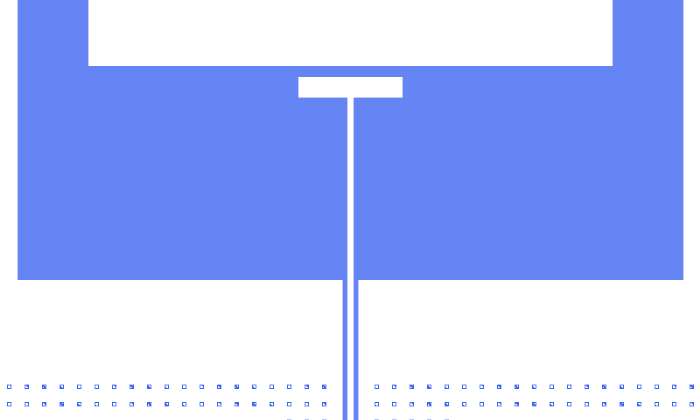

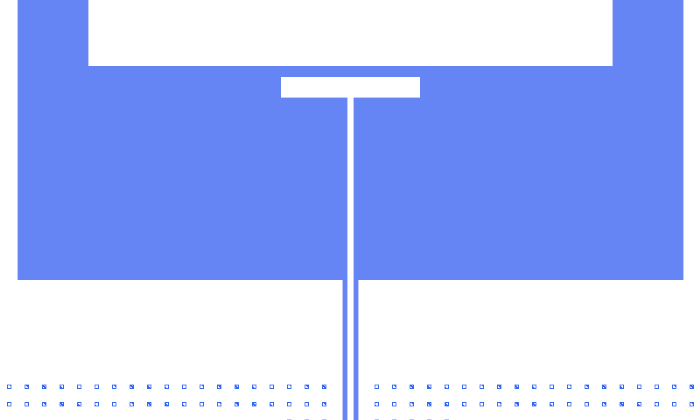

WindowsPath('examples/tutorials/img/t02_buspad_after.png')

In [18]:
d2 = Designer.load(DESIGN, live=LIVE, out="build/t02_ibm_bowtie_5q_rev1.oas")
d2["Q0"].set(connection_pads={**cpad("bus", 0, -1, 200), **cpad("ro", 0, 1, RO_PAD)})
T.built(d2)
J2 = C.exchange_coupling(d2, PAIRS["Q0-Q2"], "Q0", "Q2")
before = {"J(Q0–Q2) MHz": J["Q0-Q2"]["J_MHz"], "f_Q0 GHz": J["Q0-Q2"]["f_a_GHz"], "f_Q2 GHz": J["Q0-Q2"]["f_b_GHz"]}
after = {"J(Q0–Q2) MHz": J2["J_MHz"], "f_Q0 GHz": J2["f_a_GHz"], "f_Q2 GHz": J2["f_b_GHz"]}
T.md(T.before_after_md(before, after))
print("DRC:", "clean" if T.drc(d2).ok else "ERRORS")
box = (X["Q0"] - 500, YT + 100, X["Q0"] + 500, YT + 700)
T.snap(d, "buspad_before", box=box, size=(700, 420), width=340)
T.snap(d2, "buspad_after", box=box, size=(700, 420), width=340)

## 12 · Build and export

- `examples/tutorials/designs/t02_ibm_bowtie_5q.json` is the design; `qcc build` rebuilds it, `qcc mask` writes the
  fab file.
- `export_fab`: PDK fab layers, the build's cheese (the PDK band: the source has none), rounded corners.
- Simulation exports: no cheese; this chip has no airbridges.

CLI: `qcc build examples/tutorials/designs/t02_ibm_bowtie_5q.json`, `qcc design drc …`, `qcc sim build … -g
triangle_A -a q3d_cmatrix`, `qcc hfss render … -g Q2_read -a eigenmode_epr --solve`, `qcc mask …`.

In [19]:
import warnings
from quantcore_circuits.layouts.wafers.fab_export import export_fab

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    rep_fab = {}
    fab = export_fab(T.built(d), "build/t02_ibm_bowtie_5q_fab.oas", report=rep_fab)
T.md(T.fab_report_md(rep_fab, fab))

`build/t02_ibm_bowtie_5q_fab.oas`: cheese **build** (11106 holes)

| fab layer | polygons |
|---|---|
| `CHIP_BOUNDARY` | 1 |
| `HSQ` | 10 |
| `JJ_BENT` | 5 |
| `JJ_STRAIGHT` | 5 |
| `M1` | 11112 |
| `M3` | 11112 |
| `MARKERS_ALIGN` | 36 |
| `MARKERS_DICING` | 4 |
| `SPACER_1` | 10 |
| `SPACER_2` | 10 |
| `SPACER_3` | 10 |

## 13 · Snapshots

The left triangle (two pockets, the tee and its stubs, the bus meander, Q2), Q2's trilayer junction across the pad
gap, a readout's finger capacitor and pad, and the fab view of Q2's pocket (cheese band, 3/0 keep-out).

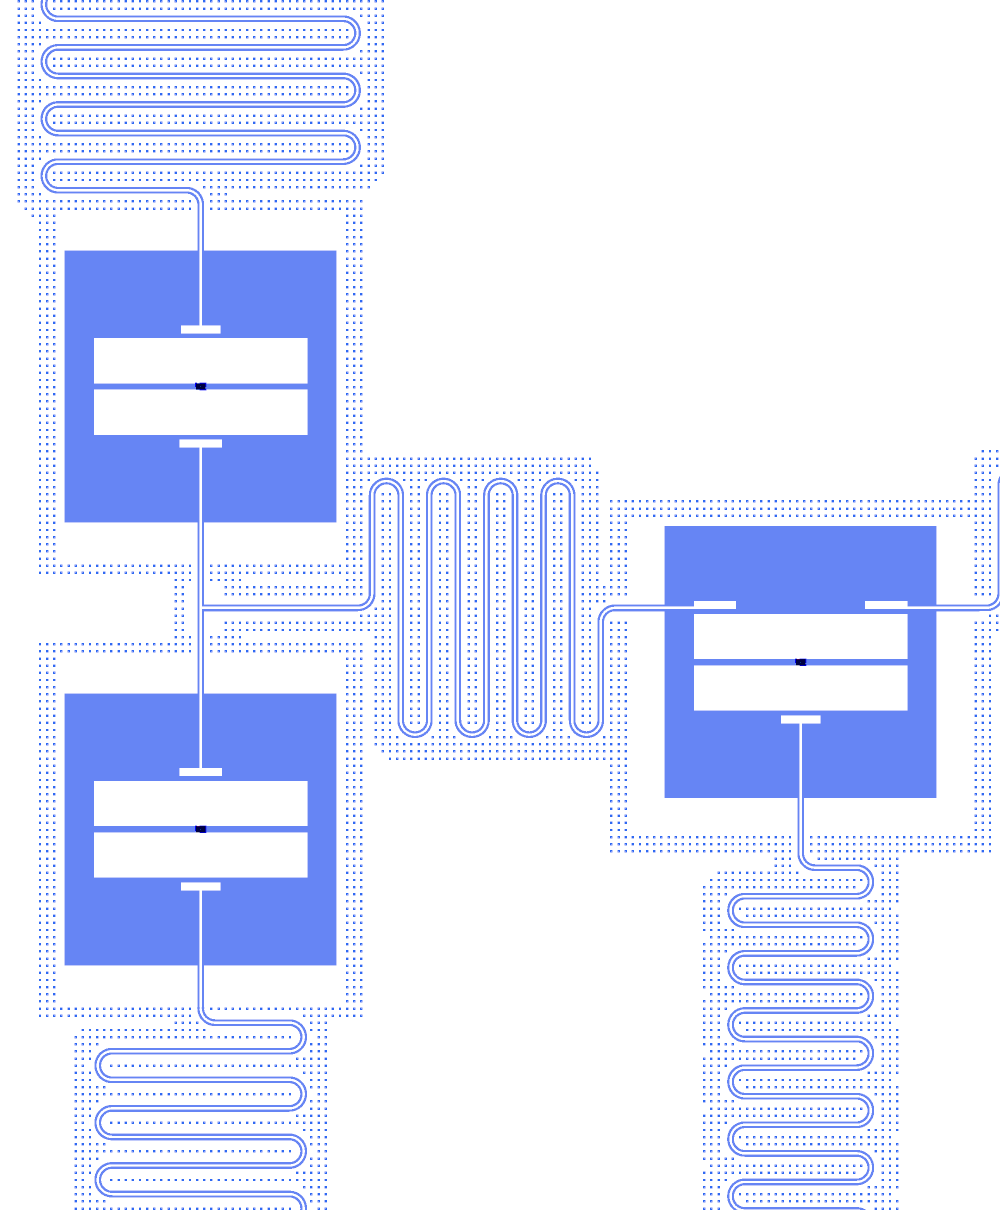

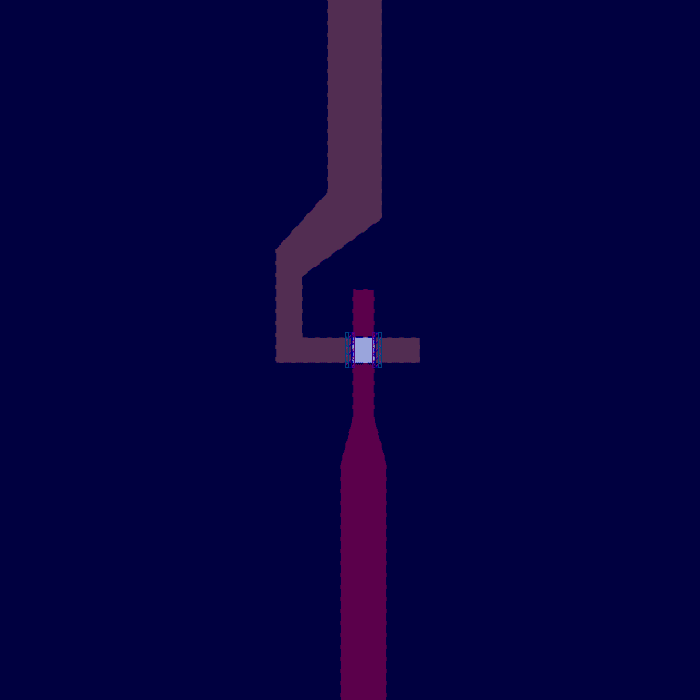

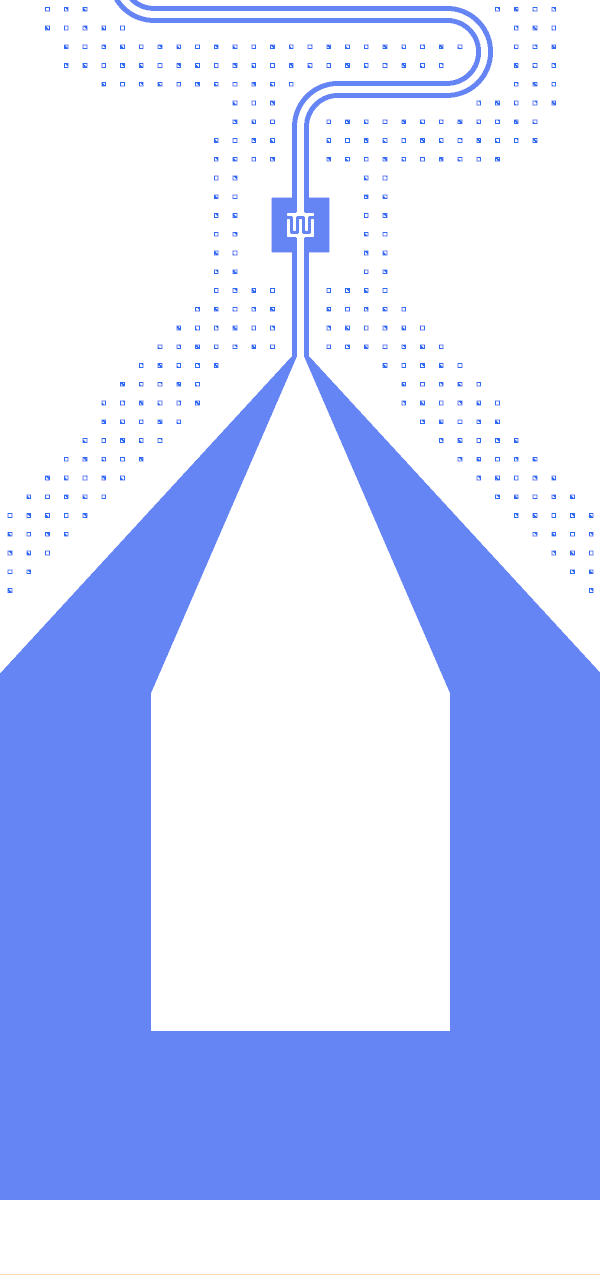

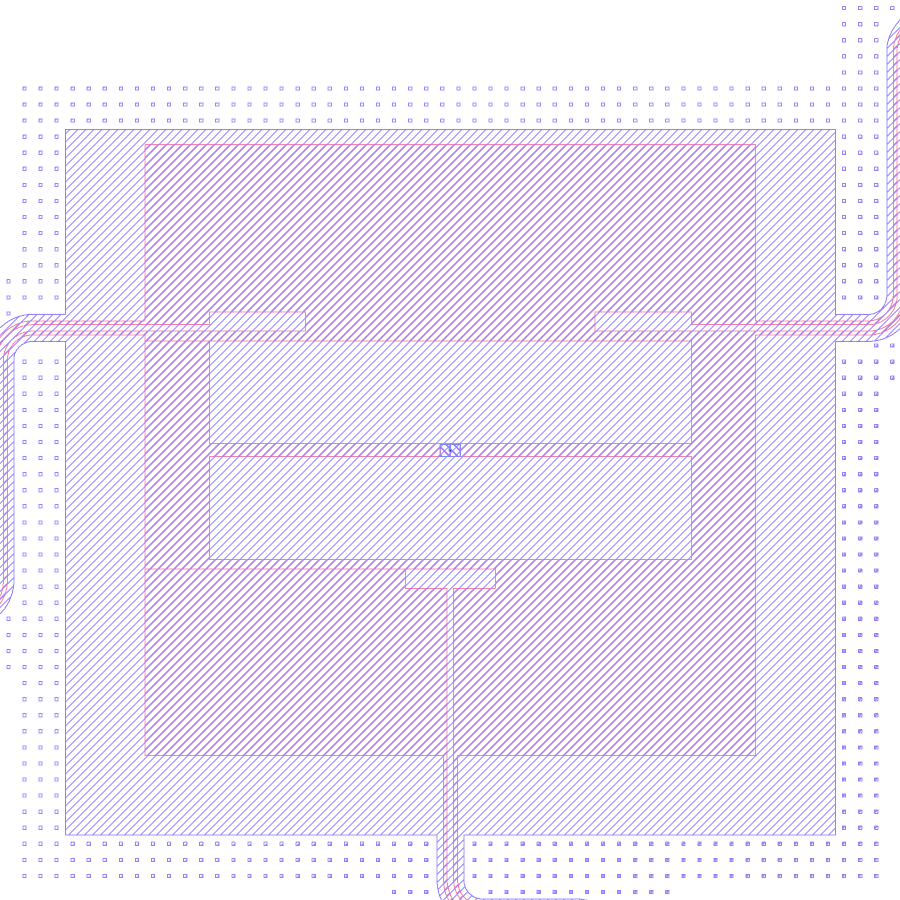

WindowsPath('examples/tutorials/img/t02_fab_q2.png')

In [20]:
T.snap(d, "triangle", box=(XC - DX - 700, YC - 1500, XC + 700, YC + 1900), size=(1000, 1210), width=440)
T.snap(d, "junction", box=T.junction_box(d, "Q2"), size=(700, 700), width=280)
T.snap(d, "cap", box=(XC - 400, 0, XC + 400, 1700), size=(600, 1275), width=260)
T.snap(d, "fab_q2", box=(XC - 700, YC - 700, XC + 700, YC + 700), size=(900, 900), width=400, source=fab)

## 14 · Summary

| | |
|---|---|
| **matches the source** | topology (two triangles through two buses), five readouts with individual lines, f_q and f_r targets, J at IBM's 1–2 MHz scale |
| **differs** | α ≈ −145 MHz instead of −330 MHz (PDK junction window); the layout is ours (no public layout) |
| **PDK** | trilayer junctions R_n 44–48 kΩ; pads 100 µm from the edge; QCT frame; PDK cheese band |
| **DRC** | 0 errors, 0 PDK design warnings |
| **FEM** | stage 1: the `SIM_SUBSET` boxes (Q3D + qubit-only eigenmode) and their check; stage 2: their values in the whole netlist (the rest estimates) → LOM on the whole netlist vs FEM → feedback on all five qubits, readouts and both buses → revision (DRC, fab); `FEM_WHOLE` (opt-in) fills from the whole-chip Q3D instead. `triangle_A`, `triangle_B`, `Q2_read` exported |
| **iterate** | Q0's bus pad 150 → 200 µm raises J(Q0–Q2) |

Next: **Tutorial 3** (`03_surface17.ipynb`), two 17-qubit surface-code chips from one generator.